# **TASK-6 Intelligent ML System:**

## Libraries and Dataset Loading:

In [ ]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

# Load dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df['target'] = iris.target

# Display first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## Data Exploration and Preprocessing:

In [ ]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check class distribution
print("\nTarget Distribution:")
print(df['target'].value_counts().sort_index())

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000



Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Duplicate Records: 1

Target Distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64


### Visualize the dataset:

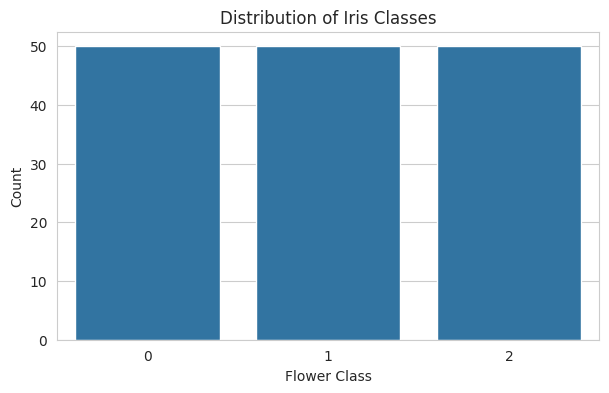

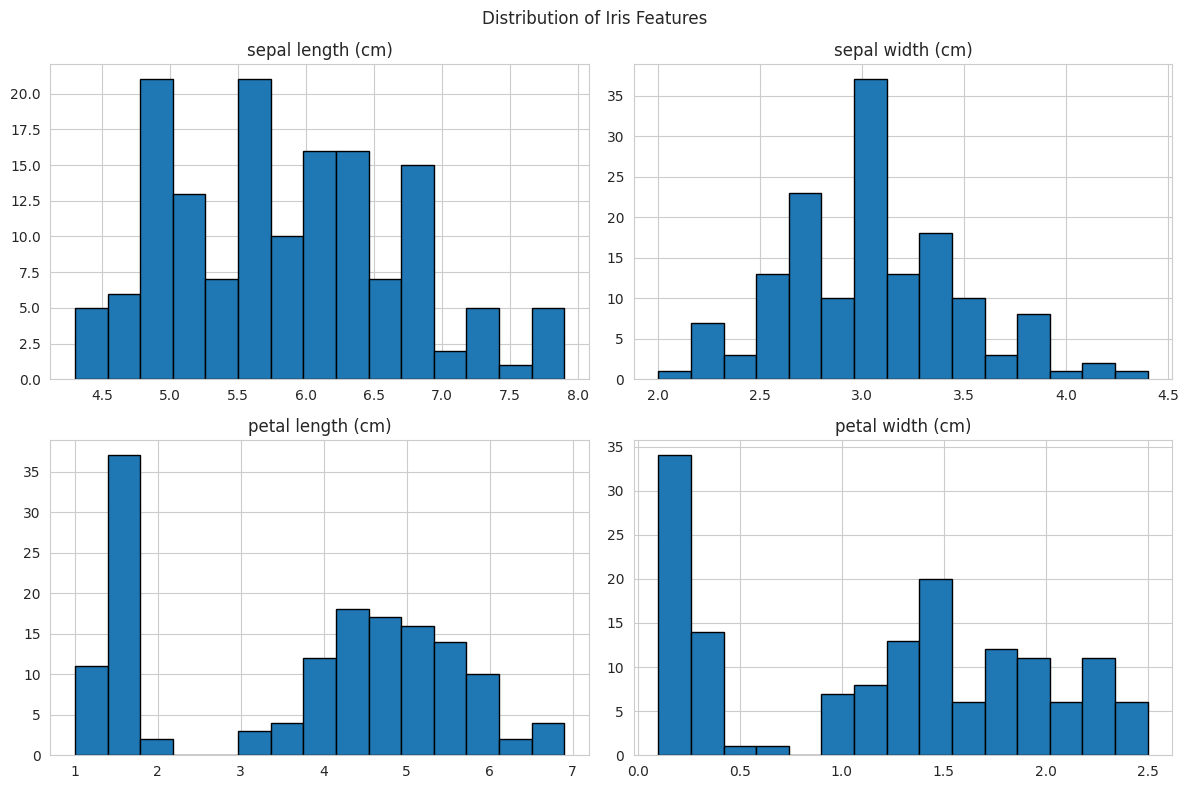

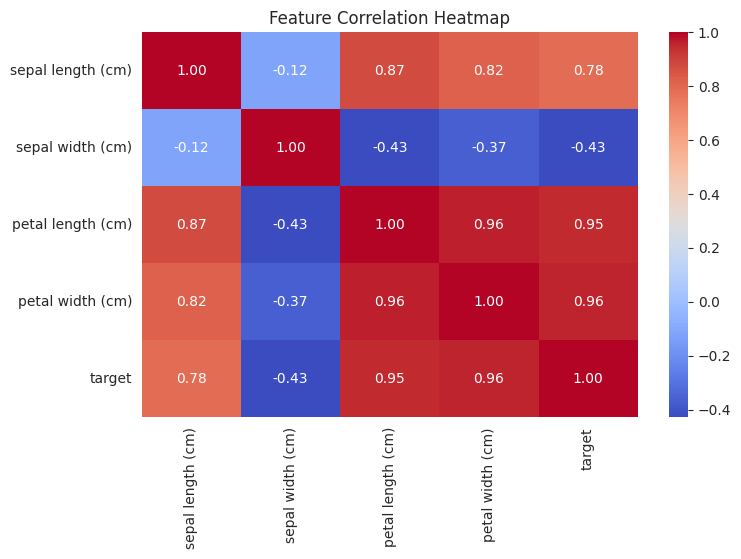

In [ ]:
# Set visualization style
sns.set_style("whitegrid")

# 1. Target distribution
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x='target'
)

plt.title("Distribution of Iris Classes")
plt.xlabel("Flower Class")
plt.ylabel("Count")
plt.show()


# 2. Feature distributions
df.iloc[:, :4].hist(
    figsize=(12, 8),
    bins=15,
    edgecolor='black'
)

plt.suptitle("Distribution of Iris Features")
plt.tight_layout()
plt.show()


# 3. Correlation heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()

### Investogate Duplicate Records:

In [ ]:
# Display duplicate records
duplicates = df[df.duplicated(keep=False)]

print("Duplicate Records:")
display(duplicates)

# Display duplicate count
print("Total Duplicate Records:", df.duplicated().sum())

Duplicate Records:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
101,5.8,2.7,5.1,1.9,2
142,5.8,2.7,5.1,1.9,2


Total Duplicate Records: 1


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Step 1: Remove duplicate records
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

# Step 2: Separate features and target
X = df.drop('target', axis=1)
y = df['target']

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

# Step 3: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Target Distribution:")
print(y_test.value_counts().sort_index())

Dataset Shape After Removing Duplicates: (149, 5)

Features Shape: (149, 4)
Target Shape: (149,)

Training Features: (119, 4)
Testing Features: (30, 4)

Training Target Distribution:
target
0    40
1    40
2    39
Name: count, dtype: int64

Testing Target Distribution:
target
0    10
1    10
2    10
Name: count, dtype: int64


## ## Classification – Three Models:

### Feature Scaling and Model Training:

In [ ]:
# Initialize StandardScaler
scaler = StandardScaler()

# Fit scaler on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Training Data Scaled:", X_train_scaled.shape)
print("Testing Data Scaled:", X_test_scaled.shape)

print("\nTraining Feature Means:")
print(X_train_scaled.mean(axis=0).round(2))

Training Data Scaled: (119, 4)
Testing Data Scaled: (30, 4)

Training Feature Means:
[-0.  0.  0.  0.]


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Initialize models
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train Logistic Regression
logistic_model.fit(X_train_scaled, y_train)

# Train Decision Tree
decision_tree_model.fit(X_train, y_train)

# Train Random Forest
random_forest_model.fit(X_train, y_train)

print("All three models trained successfully!")

All three models trained successfully!


### Generate Predictions:

In [ ]:
# Generate predictions using all three models

logistic_predictions = logistic_model.predict(X_test_scaled)

decision_tree_predictions = decision_tree_model.predict(X_test)

random_forest_predictions = random_forest_model.predict(X_test)

print("Logistic Regression Predictions:")
print(logistic_predictions)

print("\nDecision Tree Predictions:")
print(decision_tree_predictions)

print("\nRandom Forest Predictions:")
print(random_forest_predictions)

print("\nActual Values:")
print(y_test.to_numpy())

Logistic Regression Predictions:
[1 1 2 0 2 1 1 0 2 2 0 0 0 1 2 0 2 0 2 0 1 1 0 0 1 1 2 2 2 1]

Decision Tree Predictions:
[1 1 2 0 2 1 1 0 2 2 0 0 0 1 2 0 2 0 2 0 1 1 0 0 1 1 2 2 2 1]

Random Forest Predictions:
[1 1 2 0 2 1 1 0 2 2 0 0 0 1 2 0 2 0 2 0 1 1 0 0 1 1 2 2 2 1]

Actual Values:
[1 1 2 0 2 1 1 0 2 2 0 0 0 1 2 0 1 0 2 0 1 2 0 0 1 1 2 2 2 1]


## Model Comparison and Evaluation

### Calculate evaluation metrics:

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Store model predictions
predictions = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions
}

# Calculate evaluation metrics
results = []

for model_name, y_pred in predictions.items():

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted"
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted"
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="weighted"
        )
    })

# Create comparison DataFrame
results_df = pd.DataFrame(results)

print("Classification Model Comparison:")
display(results_df.round(4))

Classification Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333
2,Random Forest,0.9333,0.9333,0.9333,0.9333


### Confusion Matrices:


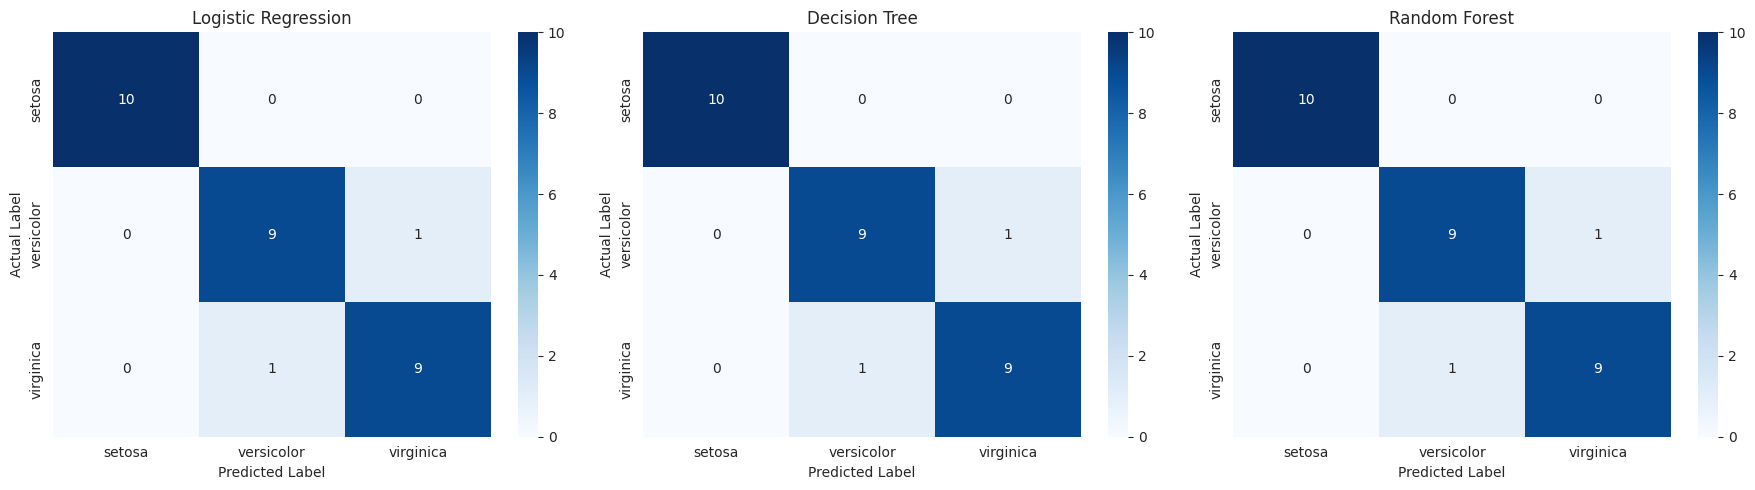


Logistic Regression - Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree - Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Random Forest - Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  vers

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Store model names and predictions
models_predictions = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions
}

# Create confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(
    axes, models_predictions.items()
):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


# Detailed classification reports
for name, predictions in models_predictions.items():
    print(f"\n{name} - Classification Report")
    print(classification_report(
        y_test,
        predictions,
        target_names=iris.target_names
    ))

## Clustering – K-Means:


### Prepare Data:

In [ ]:
from sklearn.cluster import KMeans

# Use only feature columns
X_cluster = X.copy()

# Scale features
cluster_scaler = StandardScaler()

X_cluster_scaled = cluster_scaler.fit_transform(
    X_cluster
)

print("Clustering Data Shape:", X_cluster.shape)
print("Scaled Clustering Data Shape:", X_cluster_scaled.shape)

Clustering Data Shape: (149, 4)
Scaled Clustering Data Shape: (149, 4)


### Train the K-Means model:

In [ ]:
# Initialize K-Means
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train model and assign cluster labels
cluster_labels = kmeans.fit_predict(X_cluster_scaled)

# Add cluster assignments to a copy of dataset
clustered_df = X.copy()
clustered_df['Cluster'] = cluster_labels
clustered_df['Actual Species'] = y.values

# Display results
print("K-Means Clustering Completed!")

print("\nCluster Distribution:")
print(clustered_df['Cluster'].value_counts().sort_index())

print("\nFirst 10 Cluster Assignments:")
display(clustered_df.head(10))

K-Means Clustering Completed!

Cluster Distribution:
Cluster
0    52
1    50
2    47
Name: count, dtype: int64

First 10 Cluster Assignments:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster,Actual Species
0,5.1,3.5,1.4,0.2,1,0
1,4.9,3.0,1.4,0.2,1,0
2,4.7,3.2,1.3,0.2,1,0
3,4.6,3.1,1.5,0.2,1,0
4,5.0,3.6,1.4,0.2,1,0
5,5.4,3.9,1.7,0.4,1,0
6,4.6,3.4,1.4,0.3,1,0
7,5.0,3.4,1.5,0.2,1,0
8,4.4,2.9,1.4,0.2,1,0
9,4.9,3.1,1.5,0.1,1,0


### Visualize the discovered clusters:
K-Means used four features, we'll use PCA (Principal Component Analysis) to project those four-dimensional measurements into two dimensions for visualization.

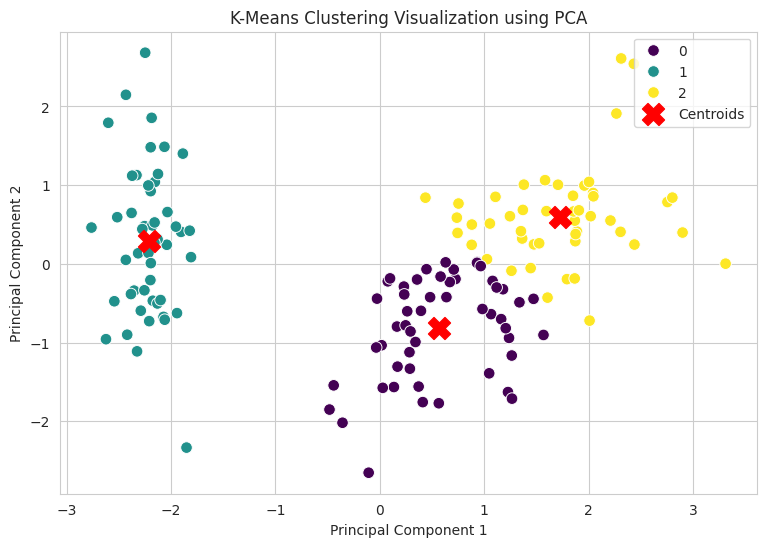

Explained Variance: 0.9585


In [ ]:
from sklearn.decomposition import PCA

# Reduce four features to two dimensions
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_cluster_scaled)

# Transform cluster centers into PCA space
centers_pca = pca.transform(kmeans.cluster_centers_)

# Create visualization
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=cluster_labels,
    palette='viridis',
    s=70
)

# Plot cluster centers
plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker='X',
    s=250,
    color='red',
    label='Centroids'
)

plt.title("K-Means Clustering Visualization using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()

# Explained variance
print(
    "Explained Variance:",
    pca.explained_variance_ratio_.sum().round(4)
)

### Evaluate clustering performance:

In [ ]:
from sklearn.metrics import silhouette_score

# Calculate silhouette score
sil_score = silhouette_score(
    X_cluster_scaled,
    cluster_labels
)

print("K-Means Silhouette Score:", round(sil_score, 4))

K-Means Silhouette Score: 0.4607


#### Compare discovered clusters with actual species:

In [ ]:
# Compare clusters with actual species
cluster_comparison = pd.crosstab(
    clustered_df['Cluster'],
    clustered_df['Actual Species'],
    rownames=['K-Means Cluster'],
    colnames=['Actual Species']
)

print("Cluster vs Actual Species Comparison:")
display(cluster_comparison)

Cluster vs Actual Species Comparison:


Actual Species,0,1,2
K-Means Cluster,,,
0,0,39,13
1,50,0,0
2,0,11,36


## Anomaly Detection – Isolation Forest:

### Train the Isolation Forest model:
We'll use contamination=0.05, meaning we're asking the model to estimate approximately 5% of observations as anomalies.

In [ ]:
from sklearn.ensemble import IsolationForest

# Initialize Isolation Forest
iso_forest = IsolationForest(
    contamination=0.05,
    random_state=42
)

# Train model and detect anomalies
anomaly_labels = iso_forest.fit_predict(X)

# Add results to dataset
anomaly_df = X.copy()

anomaly_df['Anomaly_Status'] = anomaly_labels

# Display results
print("Anomaly Detection Completed!")

print("\nDetection Summary:")

print(
    anomaly_df['Anomaly_Status']
    .value_counts()
    .rename(index={
        1: 'Normal',
        -1: 'Anomaly'
    })
)

print("\nFirst 10 Results:")
display(anomaly_df.head(10))

Anomaly Detection Completed!

Detection Summary:
Anomaly_Status
Normal     141
Anomaly      8
Name: count, dtype: int64

First 10 Results:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Anomaly_Status
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1
5,5.4,3.9,1.7,0.4,1
6,4.6,3.4,1.4,0.3,1
7,5.0,3.4,1.5,0.2,1
8,4.4,2.9,1.4,0.2,1
9,4.9,3.1,1.5,0.1,1


### Visualize detected anomalies:

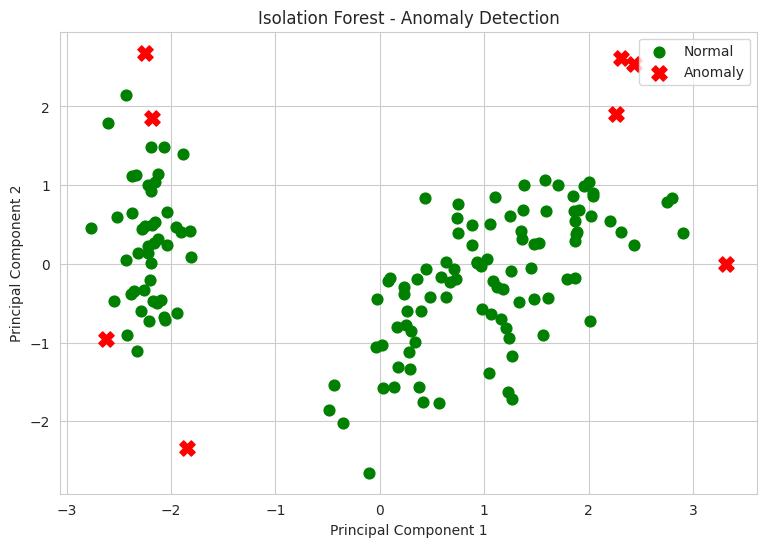

In [ ]:
from sklearn.decomposition import PCA

# Scale data for visualization
anomaly_scaler = StandardScaler()
X_anomaly_scaled = anomaly_scaler.fit_transform(X)

# Reduce dimensions using PCA
anomaly_pca = PCA(n_components=2)
X_anomaly_pca = anomaly_pca.fit_transform(
    X_anomaly_scaled
)

# Create visualization
plt.figure(figsize=(9, 6))

# Normal observations
normal_mask = anomaly_labels == 1

plt.scatter(
    X_anomaly_pca[normal_mask, 0],
    X_anomaly_pca[normal_mask, 1],
    color='green',
    label='Normal',
    s=60
)

# Anomalies
anomaly_mask = anomaly_labels == -1

plt.scatter(
    X_anomaly_pca[anomaly_mask, 0],
    X_anomaly_pca[anomaly_mask, 1],
    color='red',
    label='Anomaly',
    marker='X',
    s=120
)

plt.title("Isolation Forest - Anomaly Detection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()

### Inspect detected anomalies:
Let's also see which actual flower measurements were identified as unusual.

In [ ]:
# Extract detected anomalies
detected_anomalies = anomaly_df[
    anomaly_df['Anomaly_Status'] == -1
]

print("Detected Anomalies:")
display(detected_anomalies)

print(
    "Total Detected Anomalies:",
    len(detected_anomalies)
)

Detected Anomalies:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Anomaly_Status
13,4.3,3.0,1.1,0.1,-1
14,5.8,4.0,1.2,0.2,-1
15,5.7,4.4,1.5,0.4,-1
41,4.5,2.3,1.3,0.3,-1
109,7.2,3.6,6.1,2.5,-1
117,7.7,3.8,6.7,2.2,-1
118,7.7,2.6,6.9,2.3,-1
131,7.9,3.8,6.4,2.0,-1


Total Detected Anomalies: 8


## Reinforcement Learning – Q-Learning:

### Create the Grid World Enivornment:

In [ ]:
# Define Grid World Environment

GRID_SIZE = 4

START_STATE = (0, 0)
GOAL_STATE = (3, 3)

OBSTACLES = [(1, 1)]

# Possible actions
ACTIONS = ['up', 'down', 'left', 'right']

# Reward values
GOAL_REWARD = 10
OBSTACLE_REWARD = -10
STEP_REWARD = -1

print("Grid World Environment Created!")
print("Grid Size:", GRID_SIZE, "x", GRID_SIZE)
print("Start State:", START_STATE)
print("Goal State:", GOAL_STATE)
print("Obstacles:", OBSTACLES)
print("Available Actions:", ACTIONS)

Grid World Environment Created!
Grid Size: 4 x 4
Start State: (0, 0)
Goal State: (3, 3)
Obstacles: [(1, 1)]
Available Actions: ['up', 'down', 'left', 'right']


### Define Enviornment Rules

In [ ]:
# Define environment movement function

def take_action(state, action):

    row, col = state

    # Calculate next position
    if action == 'up':
        row -= 1

    elif action == 'down':
        row += 1

    elif action == 'left':
        col -= 1

    elif action == 'right':
        col += 1

    next_state = (row, col)

    # Check grid boundaries
    if (
        row < 0 or row >= GRID_SIZE or
        col < 0 or col >= GRID_SIZE
    ):
        return state, STEP_REWARD, False

    # Check obstacles
    if next_state in OBSTACLES:
        return state, OBSTACLE_REWARD, False

    # Check goal
    if next_state == GOAL_STATE:
        return next_state, GOAL_REWARD, True

    # Normal movement
    return next_state, STEP_REWARD, False


print("Environment movement function created!")

Environment movement function created!


### Create the Q table:

In [ ]:
import numpy as np

# Initialize Q-table
q_table = np.zeros((GRID_SIZE * GRID_SIZE, len(ACTIONS)))

# Convert grid position into a state index
def state_to_index(state):
    row, col = state
    return row * GRID_SIZE + col

print("Q-Table Created Successfully!")
print("\nQ-Table Shape:", q_table.shape)
print("\nInitial Q-Table:")
print(q_table)

Q-Table Created Successfully!

Q-Table Shape: (16, 4)

Initial Q-Table:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


### Implement Q Learning:

In [ ]:
# Q-Learning Hyperparameters

learning_rate = 0.1
discount_factor = 0.99

epsilon = 1.0
epsilon_decay = 0.995
min_epsilon = 0.01

episodes = 2000
max_steps = 100

# Store training rewards
episode_rewards = []

# Q-Learning Training
for episode in range(episodes):

    # Reset environment
    state = START_STATE

    total_reward = 0

    for step in range(max_steps):

        state_index = state_to_index(state)

        # Exploration or Exploitation
        if np.random.random() < epsilon:

            action_index = np.random.randint(len(ACTIONS))

        else:

            action_index = np.argmax(
                q_table[state_index]
            )

        action = ACTIONS[action_index]

        # Perform action
        next_state, reward, done = take_action(
            state, action
        )

        next_state_index = state_to_index(next_state)

        # Calculate Q-value update
        if done:

            target = reward

        else:

            target = reward + discount_factor * np.max(
                q_table[next_state_index]
            )

        # Update Q-table
        q_table[state_index, action_index] += (
            learning_rate *
            (target - q_table[state_index, action_index])
        )

        state = next_state

        total_reward += reward

        if done:
            break

    # Store episode reward
    episode_rewards.append(total_reward)

    # Reduce exploration
    epsilon = max(
        min_epsilon,
        epsilon * epsilon_decay
    )

print("Q-Learning Training Completed!")

print("Total Episodes:", episodes)
print("Final Exploration Rate:", round(epsilon, 4))

print("\nFinal Q-Table:")
print(np.round(q_table, 2))

Q-Learning Training Completed!
Total Episodes: 2000
Final Exploration Rate: 0.01

Final Q-Table:
[[ 3.48  4.28  3.5   4.61]
 [ 4.58 -4.46  3.51  5.67]
 [ 5.59  6.73  4.5   6.38]
 [ 2.    7.74  3.47  3.87]
 [ 0.26  5.56  1.68 -7.79]
 [ 0.    0.    0.    0.  ]
 [ 5.41  7.81 -2.48  7.75]
 [ 4.95  8.9   4.68  6.66]
 [ 0.55  2.43  2.58  6.71]
 [-3.62  5.26  2.87  7.81]
 [ 6.67  8.9   6.64  8.89]
 [ 7.22 10.    6.15  8.  ]
 [ 0.41  0.53  1.17  6.24]
 [ 4.71  2.81  2.15  8.86]
 [ 7.78  8.82  7.49 10.  ]
 [ 0.    0.    0.    0.  ]]


### Visulaize the Learning Progree:

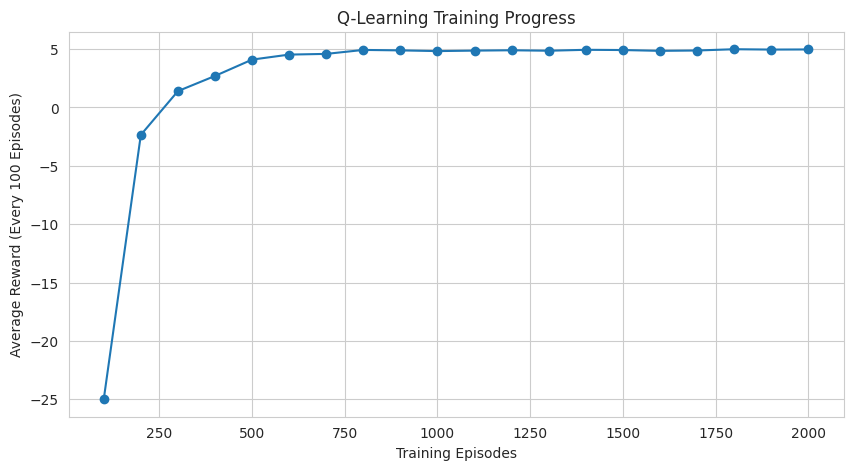

First 100 Episodes Average Reward: -25.0
Last 100 Episodes Average Reward: 4.97


In [ ]:
# Calculate average reward every 100 episodes

rewards_array = np.array(episode_rewards)

average_rewards = []

for i in range(0, episodes, 100):

    batch_rewards = rewards_array[i:i+100]

    average_rewards.append(
        np.mean(batch_rewards)
    )

# Plot training progress

plt.figure(figsize=(10, 5))

plt.plot(
    range(100, episodes + 1, 100),
    average_rewards,
    marker='o'
)

plt.title("Q-Learning Training Progress")
plt.xlabel("Training Episodes")
plt.ylabel("Average Reward (Every 100 Episodes)")

plt.grid(True)
plt.show()

print("First 100 Episodes Average Reward:",
      round(average_rewards[0], 2))

print("Last 100 Episodes Average Reward:",
      round(average_rewards[-1], 2))

### Test the Trained Agent:

In [ ]:
# Test trained agent without exploration

state = START_STATE

agent_path = [state]
total_test_reward = 0

max_test_steps = 30

for step in range(max_test_steps):

    # Get current state index
    state_index = state_to_index(state)

    # Select best learned action
    action_index = np.argmax(q_table[state_index])

    action = ACTIONS[action_index]

    # Perform action
    next_state, reward, done = take_action(
        state, action
    )

    total_test_reward += reward

    print(
        f"Step {step + 1}: "
        f"State={state}, "
        f"Action={action}, "
        f"Reward={reward}, "
        f"Next State={next_state}"
    )

    state = next_state
    agent_path.append(state)

    if done:
        print("\nGoal Reached Successfully!")
        break

else:
    print("\nAgent could not reach the goal.")

print("\nLearned Path:", agent_path)
print("Total Steps:", len(agent_path) - 1)
print("Total Test Reward:", total_test_reward)

Step 1: State=(0, 0), Action=right, Reward=-1, Next State=(0, 1)
Step 2: State=(0, 1), Action=right, Reward=-1, Next State=(0, 2)
Step 3: State=(0, 2), Action=down, Reward=-1, Next State=(1, 2)
Step 4: State=(1, 2), Action=down, Reward=-1, Next State=(2, 2)
Step 5: State=(2, 2), Action=down, Reward=-1, Next State=(3, 2)
Step 6: State=(3, 2), Action=right, Reward=10, Next State=(3, 3)

Goal Reached Successfully!

Learned Path: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (3, 2), (3, 3)]
Total Steps: 6
Total Test Reward: 5


### Visualize the Learned Path:

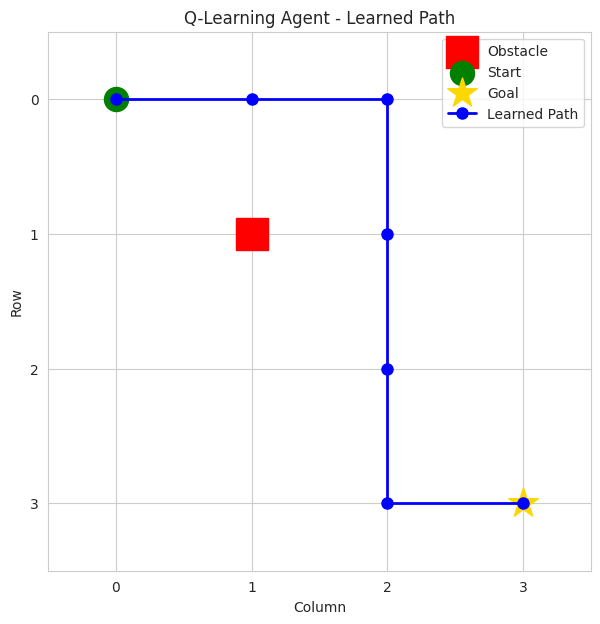

In [ ]:
# Visualize the learned path

plt.figure(figsize=(7, 7))

# Draw grid
plt.xlim(-0.5, 3.5)
plt.ylim(3.5, -0.5)

plt.xticks(range(4))
plt.yticks(range(4))
plt.grid(True)

# Mark obstacle
for row, col in OBSTACLES:
    plt.scatter(
        col, row,
        color='red',
        marker='s',
        s=500,
        label='Obstacle'
    )

# Mark start and goal
plt.scatter(
    START_STATE[1], START_STATE[0],
    color='green',
    marker='o',
    s=300,
    label='Start'
)

plt.scatter(
    GOAL_STATE[1], GOAL_STATE[0],
    color='gold',
    marker='*',
    s=500,
    label='Goal'
)

# Draw learned path
path_x = [state[1] for state in agent_path]
path_y = [state[0] for state in agent_path]

plt.plot(
    path_x,
    path_y,
    color='blue',
    linewidth=2,
    marker='o',
    markersize=8,
    label='Learned Path'
)

plt.title("Q-Learning Agent - Learned Path")
plt.xlabel("Column")
plt.ylabel("Row")
plt.legend()
plt.show()

### Test Agent Reliability:

In [ ]:
# Test agent across 100 episodes

test_episodes = 100

success_count = 0
test_steps_list = []
test_rewards_list = []

for episode in range(test_episodes):

    state = START_STATE
    total_reward = 0

    for step in range(30):

        state_index = state_to_index(state)

        # Greedy action selection
        action_index = np.argmax(q_table[state_index])
        action = ACTIONS[action_index]

        next_state, reward, done = take_action(
            state, action
        )

        total_reward += reward
        state = next_state

        if done:
            success_count += 1
            test_steps_list.append(step + 1)
            break

    test_rewards_list.append(total_reward)

# Calculate performance
success_rate = (success_count / test_episodes) * 100

print("Agent Reliability Evaluation")
print("----------------------------")
print("Total Test Episodes:", test_episodes)
print("Successful Episodes:", success_count)
print("Success Rate:", success_rate, "%")
print("Average Steps:", np.mean(test_steps_list))
print("Average Reward:", np.mean(test_rewards_list))

Agent Reliability Evaluation
----------------------------
Total Test Episodes: 100
Successful Episodes: 100
Success Rate: 100.0 %
Average Steps: 6.0
Average Reward: 5.0
